# Model Comparison Analysis: Baseline vs. Neural M-Signal

This notebook evaluates and compares two different architectures developed for idiomaticity signal (M-Signal) prediction.

### Analyzed Architectures

*   **Baseline Model:** A classifier that uses only the pooled embedding vectors of the target idiom (Target) as input to predict the binary idiomaticity label.
*   **Neural M-Signal Model:** An advanced MLP architecture trained on 3072-dimensional concatenated vectors, incorporating multi-dimensional features such as original context, dictionary definitions, paraphrases, and lexical substitutions.

### Evaluation Metrics

Model performance is analyzed quantitatively using Loss curves, F1-Score, Accuracy, and ROC-AUC values.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Visualization settings
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 150
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)

### Data Loading and Preprocessing

Performance data saved in `output/metrics.json` files from the training processes are loaded and consolidated into a single DataFrame for comparative analysis.

In [2]:
def load_metrics(json_path):
    path = Path(json_path)
    if not path.exists():
        return None
    with open(path, "r") as f:
        return json.load(f)

# Define paths in the unified directory structure
baseline_data = load_metrics("baseline/output/metrics.json")
neural_data = load_metrics("llm/output/metrics.json")

if not baseline_data:
    print("Warning: Baseline metrics not found. Please run the baseline training first.")
if not neural_data:
    print("Warning: Neural M metrics not found. Please run the neural M training first.")

df_list = []

if baseline_data and "history" in baseline_data:
    for epoch_data in baseline_data["history"]:
        val_data = epoch_data.get("val", epoch_data)
        df_list.append({
            "Model": "Baseline (Target Only)",
            "Epoch": epoch_data["epoch"],
            "Train Loss": epoch_data.get("train_loss"),
            "Val Loss": val_data.get("loss", val_data.get("val_loss")),
            "Val F1": val_data.get("f1"),
            "Val Accuracy": val_data.get("accuracy"),
            "Val AUC": val_data.get("roc_auc")
        })

if neural_data and "history" in neural_data:
    for epoch_data in neural_data["history"]:
        df_list.append({
            "Model": "Neural M (Concat + MLP)",
            "Epoch": epoch_data["epoch"],
            "Train Loss": epoch_data.get("train_loss"),
            "Val Loss": epoch_data.get("val_loss", epoch_data.get("loss")),
            "Val F1": epoch_data.get("f1"),
            "Val Accuracy": epoch_data.get("accuracy"),
            "Val AUC": epoch_data.get("roc_auc")
        })

df = pd.DataFrame(df_list)

### Performance Summary Table

The following table summarizes the key performance metrics for both models, based on the epoch with the highest Val-F1 score. Background coloring is used to highlight performance differences.

In [3]:
if not df.empty:
    # Find the best epoch for each model based on Val F1
    best_df = df.loc[df.groupby("Model")["Val F1"].idxmax()]
    display(best_df[["Model", "Epoch", "Val F1", "Val Accuracy", "Val AUC"]].set_index("Model")\
            .style.format("{:.3f}", na_rep="-")\
            .background_gradient(cmap="viridis", axis=0))

,Epoch,Val F1,Val Accuracy,Val AUC
Model,,,,
Baseline (Target Only),24.000,0.824,0.846,0.898
Neural M (Concat + MLP),9.000,0.802,0.816,0.868


### Training and Validation Loss Curves

Learning dynamics and potential overfitting trends are examined through the epoch-based changes in training and validation loss values. Stable and low validation loss indicates good generalization ability.

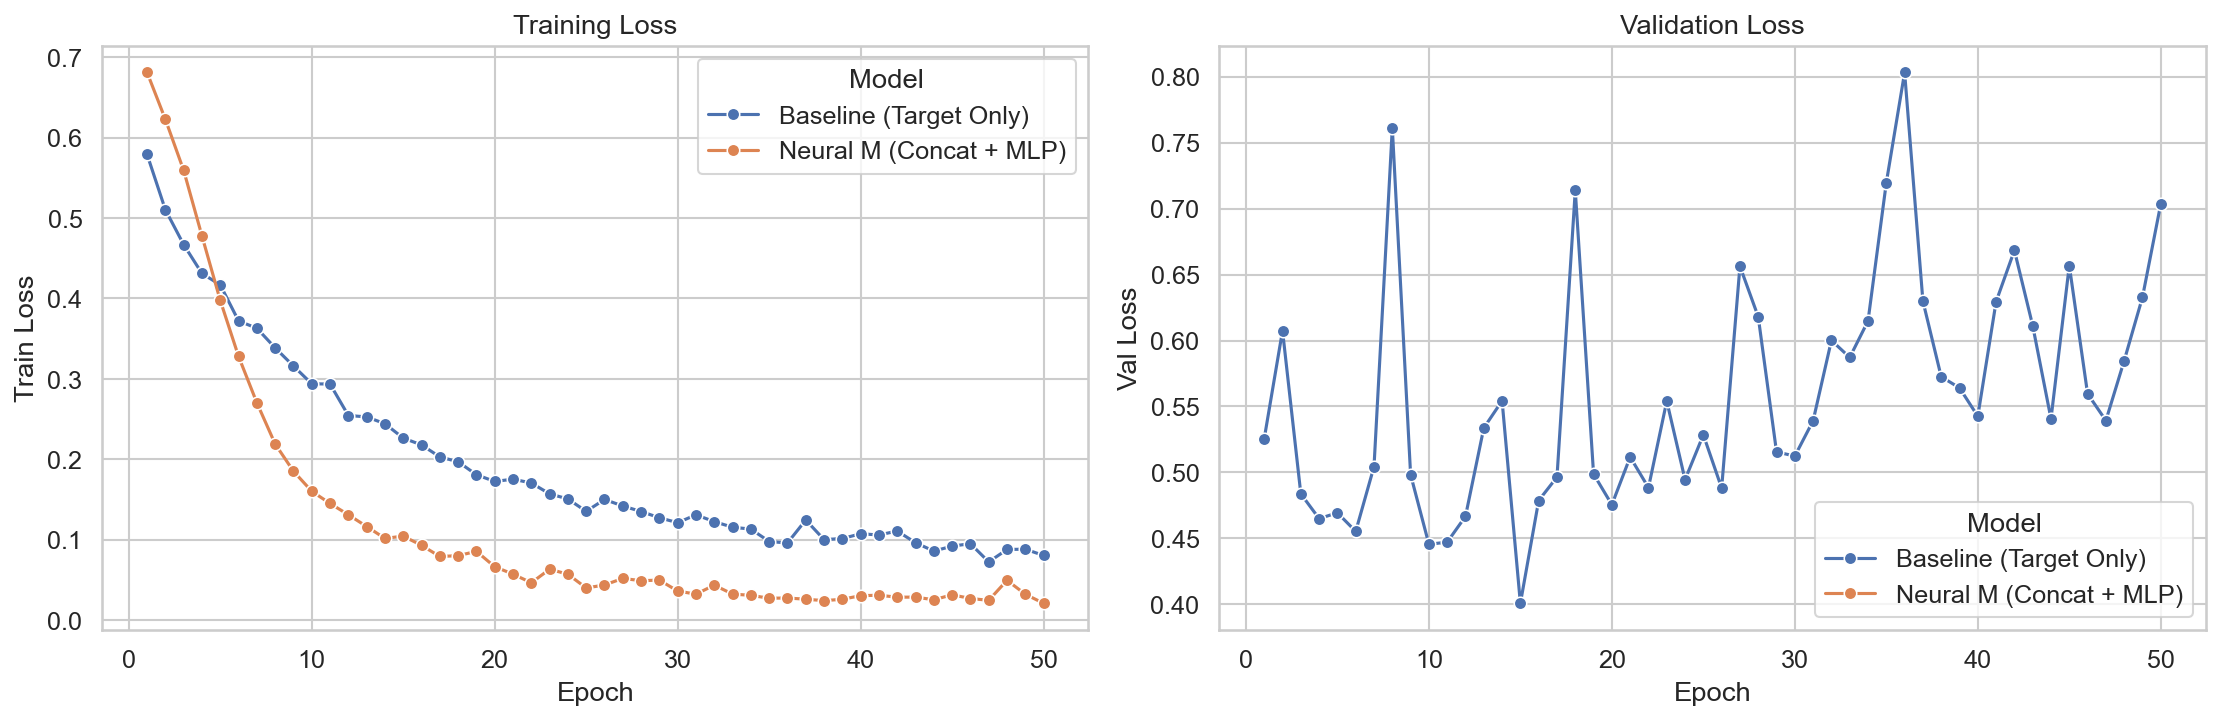

In [4]:
if not df.empty:
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    
    sns.lineplot(data=df, x="Epoch", y="Train Loss", hue="Model", marker="o", ax=ax[0])
    ax[0].set_title("Training Loss")
    
    sns.lineplot(data=df, x="Epoch", y="Val Loss", hue="Model", marker="o", ax=ax[1])
    ax[1].set_title("Validation Loss")
    
    plt.tight_layout()
    plt.show()

### Metric Distribution (F1 and AUC)

Validation F1 score, representing the balance between precision and recall, and the ROC-AUC score, indicating classification power, are visualized over the training epochs.

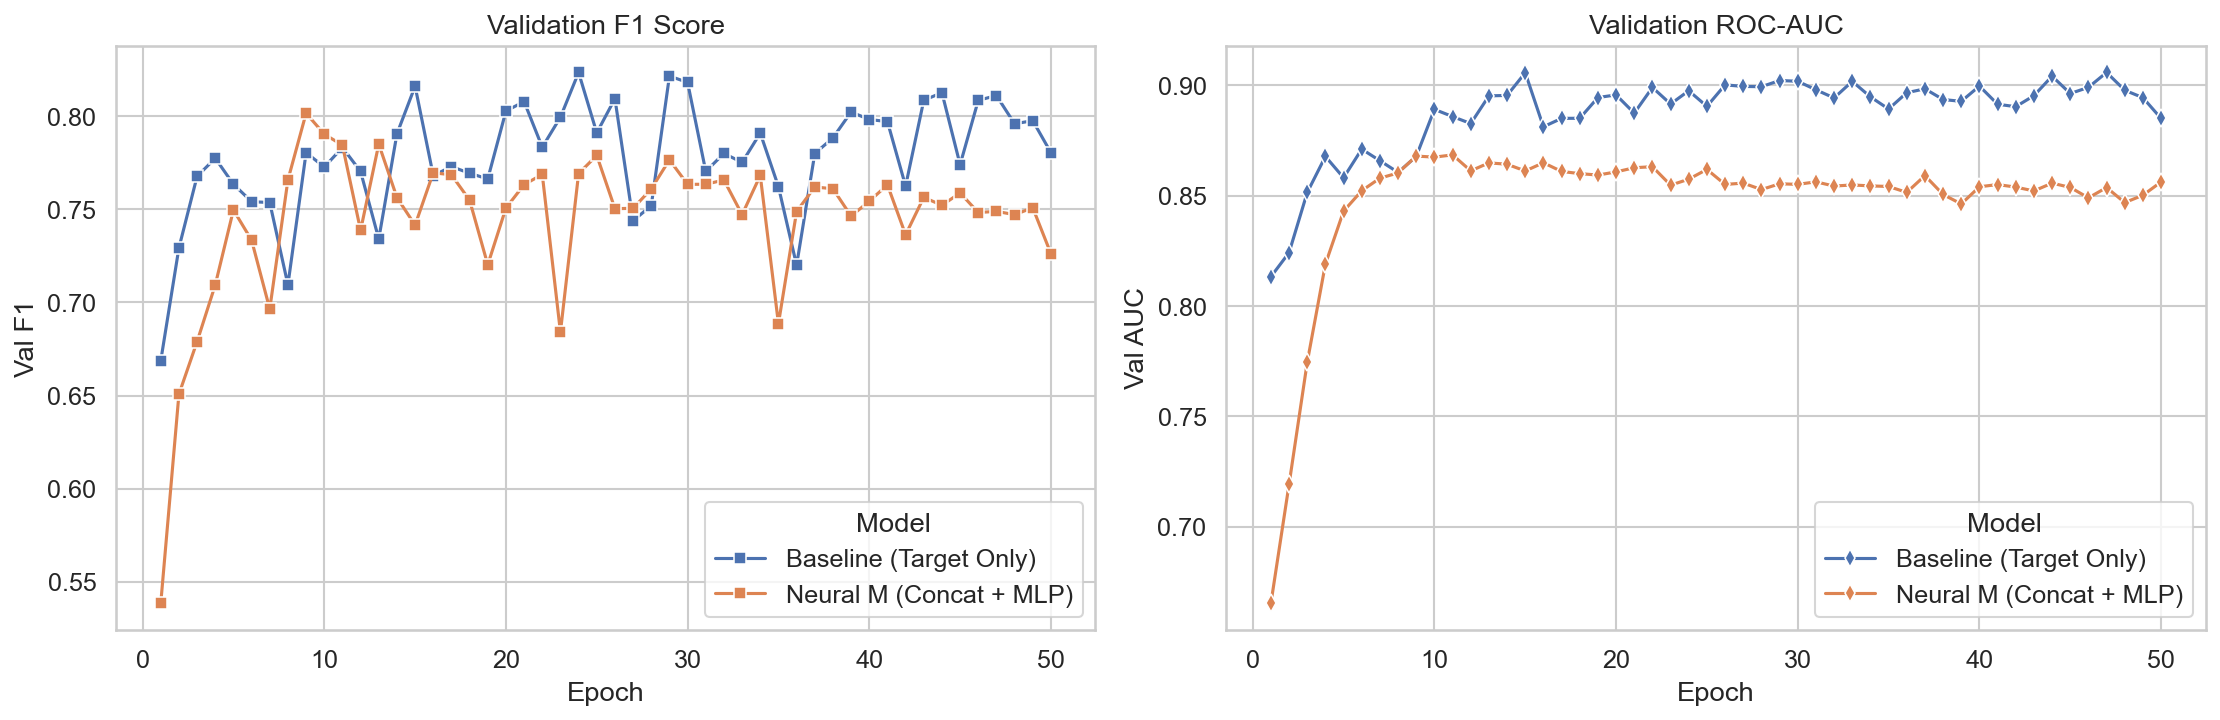

In [5]:
if not df.empty:
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    
    sns.lineplot(data=df, x="Epoch", y="Val F1", hue="Model", marker="s", ax=ax[0])
    ax[0].set_title("Validation F1 Score")
    
    sns.lineplot(data=df, x="Epoch", y="Val AUC", hue="Model", marker="d", ax=ax[1])
    ax[1].set_title("Validation ROC-AUC")
    
    plt.tight_layout()
    plt.show()